<a href="https://colab.research.google.com/github/MichelNascimento/Aula-Branch/blob/main/MVP_An%C3%A1lise_de_Dados_e_Boas_Pr%C3%A1ticas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MVP Análise de Dados e Boas Práticas

**Nome:** Michel Lopes Nascimento

**Matrícula:** 4052025000229

**Dataset:** [Telemetria de embarcação](https://github.com/MichelNascimento/MVP_Analise_Dados/raw/refs/heads/main/telemetria_rebocador.parquet)

# Descrição do Problema

O conjunto de dados é um histórico multivariado de séries temporais gerado por sensores de telemetria (dados de uma embarcação). Ele rastreia métricas de desempenho de motores principais (Bombordo/PS e Boreste/SB), geradores e sistemas de exaustão. O objetivo principal deste MVP é analisar e identificar a faixa ideal de rotação (RPM) dos motores principais — representados pelas variáveis ME_PS_SPEED_TACH_1 e ME_SB_SPEED_TACH_1 — que proporcione a maior eficiência energética, resultando no melhor (menor) consumo médio de combustível (ME_PS_AVG_FUEL_CONSUMPTION_RATE e ME_SB_AVG_FUEL_CONSUMPTION_RATE).

## Hipóteses do Problema

As hipóteses traçadas para este MVP são as seguintes:

Existe uma faixa operacional específica de RPM em que os motores entregam a melhor relação de eficiência entre trabalho gerado e combustível consumido.

O consumo de combustível não escala de forma perfeitamente linear com o RPM; operar os motores em suas rotações máximas gera um desperdício de combustível desproporcional.

O comportamento de eficiência energética é simétrico entre o motor de Bombordo (PS) e o motor de Boreste (SB), o que significa que a faixa ideal de RPM descoberta para um deve se aplicar ao outro.

## Tipo de Problema

Este é um problema de **classificação supervisionada**. Com foco e, otimização no consumo de combustível.

## Seleção de Dados

O dataset é composto por dados temporais ricos (mais de 1,3 milhão de registros e 26 colunas de telemetria). Para o escopo deste MVP, não será necessário utilizar todas as colunas. A seleção de dados focará em:

Variável de tempo (ISO Date) para entender a janela de operação.

Variáveis de RPM (ME_PS_SPEED_TACH_1, ME_SB_SPEED_TACH_1).

Variáveis de Consumo (ME_PS_AVG_FUEL_CONSUMPTION_RATE, ME_SB_AVG_FUEL_CONSUMPTION_RATE).

## Atributos do Dataset

O dataset contém 1.300.726 amostras, com dados de uma embarcação.
Possui 26 atributos:

```
- 'GENERATOR_PS_FUEL_RATE' = GERADOR BB CONSUMO DE COMBUSTIVEL
- 'GENERATOR_SB_FUEL_RATE' = GERADOR BE CONSUMO DE COMBUSTIVEL
- 'GPS_VTG_SPEED_OVER_GROUND_KNOTS' = VELOCIDADE SOBRE O FUNDO GPSKNOTS
- 'ISO Date' = DATAHORA REGISTRO
- 'ME_PS_AFTERCOOLER_TEMP' = MCP BB TEMPERATURA AFTERCOOLER
- 'ME_PS_AVG_FUEL_CONSUMPTION_RATE' = MCP BB CONSUMO COMBUSTIVEL L/H
- 'ME_PS_ENGINE_LOAD' = MCP BB CARGA MOTOR %
- 'ME_PS_EXHAUST_GAS_TEMP_MANIFOLD_EVEN' = MCP BB TEMP GAS ESCAPE MANIFOLD PAR
- 'ME_PS_EXHAUST_GAS_TEMP_MANIFOLD_ODD' = MCP BB TEMP GAS ESCAPE MANIFOLD IMPAR
- 'ME_PS_JW_COOLANT_PRESSURE' = MCP BB PRESSAO AGUA REFRIG
- 'ME_PS_JW_COOLANT_TEMP' = MCP BB TEMPERATURA AGUA REFRIG
- 'ME_PS_OIL_PRESSURE' = MCP BB PRESSAO OLEO
- 'ME_PS_OIL_TEMP' = MCP BB TEMPERATURA OLEO
- 'ME_PS_SPEED_TACH_1' = MCP BB RPM TACOMETRO 1
- 'ME_SB_AFTERCOOLER_TEMP' = MCP BE TEMPERATURA AFTERCOOLER
- 'ME_SB_AVG_FUEL_CONSUMPTION_RATE' = MCP BE CONSUMO COMBUSTIVEL L/H
- 'ME_SB_ENGINE_LOAD' = MCP BE CARGA MOTOR %
- 'ME_SB_EXHAUST_GAS_TEMP_MANIFOLD_EVEN' = MCP BE TEMP GAS ESCAPE MANIFOLD PAR
- 'ME_SB_EXHAUST_GAS_TEMP_MANIFOLD_ODD' = MCP BE TEMP GAS ESCAPE MANIFOLD IMPAR
- 'ME_SB_JW_COOLANT_PRESSURE' = MCP BE PRESSAO AGUA REFRIG
- 'ME_SB_JW_COOLANT_TEMP' = MCP BE TEMPERATURA AGUA REFRIG
- 'ME_SB_OIL_PRESSURE' = MCP BE PRESSAO OLEO
- 'ME_SB_OIL_TEMP' = MCP BE TEMPERATURA OLEO
- 'ME_SB_SPEED_TACH_1' = MCP BE RPM TACOMETRO 1
- 'RUDD_PROP_PS_ACTUAL_RPM' = ROTACAO_ATUAL_HELICE_BB
- 'RUDD_PROP_SB_ACTUAL_RPM' = ROTACAO_ATUAL_HELICE_BE
```


# Importação das Bibliotecas Necessárias e Carga de Dados

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder
from sklearn.decomposition import PCA
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)

In [2]:
# carregamento do dataset no dataframe
url = "https://raw.githubusercontent.com/MichelNascimento/MVP_Analise_Dados/main/telemetria_rebocador.parquet"
df = pd.read_parquet(url)

In [3]:
# primeiras linhas
df.head()

,GENERATOR_PS_FUEL_RATE,GENERATOR_SB_FUEL_RATE,GPS_VTG_SPEED_OVER_GROUND_KNOTS,ISO Date,ME_PS_AFTERCOOLER_TEMP,ME_PS_AVG_FUEL_CONSUMPTION_RATE,ME_PS_ENGINE_LOAD,ME_PS_EXHAUST_GAS_TEMP_MANIFOLD_EVEN,ME_PS_EXHAUST_GAS_TEMP_MANIFOLD_ODD,ME_PS_JW_COOLANT_PRESSURE,ME_PS_JW_COOLANT_TEMP,ME_PS_OIL_PRESSURE,ME_PS_OIL_TEMP,ME_PS_SPEED_TACH_1,ME_SB_AFTERCOOLER_TEMP,ME_SB_AVG_FUEL_CONSUMPTION_RATE,ME_SB_ENGINE_LOAD,ME_SB_EXHAUST_GAS_TEMP_MANIFOLD_EVEN,ME_SB_EXHAUST_GAS_TEMP_MANIFOLD_ODD,ME_SB_JW_COOLANT_PRESSURE,ME_SB_JW_COOLANT_TEMP,ME_SB_OIL_PRESSURE,ME_SB_OIL_TEMP,ME_SB_SPEED_TACH_1,RUDD_PROP_PS_ACTUAL_RPM,RUDD_PROP_SB_ACTUAL_RPM
0,0.0,16.9,0.2,2023-11-15 00:00:09,34.6,0.0,0.0,60.6,63.3,87.0,56.6,0.0,522.0,0.0,33.1,0.0,0.0,69.7,67.1,79.0,57.4,0.005,528.0,0.0,0.0,0.0
1,0.0,16.9,0.2,2023-11-15 00:00:09,34.6,0.0,0.0,60.6,63.3,87.0,56.6,0.0,522.0,0.0,33.1,0.0,0.0,69.7,67.1,79.0,57.4,0.005,528.0,0.0,0.0,0.0
2,0.0,18.0,0.2,2023-11-15 00:00:29,34.0,0.0,0.0,59.6,63.3,87.0,55.9,0.0,522.0,0.0,33.1,0.0,0.0,69.9,67.1,79.0,57.4,0.005,528.0,0.0,0.0,0.0
3,0.0,18.0,0.2,2023-11-15 00:00:29,34.0,0.0,0.0,59.6,63.3,87.0,55.9,0.0,522.0,0.0,33.1,0.0,0.0,69.9,67.1,79.0,57.4,0.005,528.0,0.0,0.0,0.0
4,0.0,17.4,0.3,2023-11-15 00:00:49,34.0,0.0,0.0,60.4,63.3,88.0,56.6,0.0,522.0,0.0,33.1,0.0,0.0,69.7,67.1,79.0,57.4,0.005,526.0,0.0,0.0,0.0


# Análise de Dados

## Total e Tipo das Instâncias

In [4]:
print(f"Total de instâncias: {len(df)}")
print("\nTipos de dados por coluna:")
print(df.info())

Total de instâncias: 1300726

Tipos de dados por coluna:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1300726 entries, 0 to 1300725
Data columns (total 26 columns):
 #   Column                                Non-Null Count    Dtype         
---  ------                                --------------    -----         
 0   GENERATOR_PS_FUEL_RATE                1300726 non-null  float64       
 1   GENERATOR_SB_FUEL_RATE                1300726 non-null  float64       
 2   GPS_VTG_SPEED_OVER_GROUND_KNOTS       1300726 non-null  float64       
 3   ISO Date                              1300726 non-null  datetime64[ns]
 4   ME_PS_AFTERCOOLER_TEMP                1300726 non-null  float64       
 5   ME_PS_AVG_FUEL_CONSUMPTION_RATE       1300726 non-null  float64       
 6   ME_PS_ENGINE_LOAD                     1300726 non-null  float64       
 7   ME_PS_EXHAUST_GAS_TEMP_MANIFOLD_EVEN  1300726 non-null  float64       
 8   ME_PS_EXHAUST_GAS_TEMP_MANIFOLD_ODD   1300726 non-null  float64  

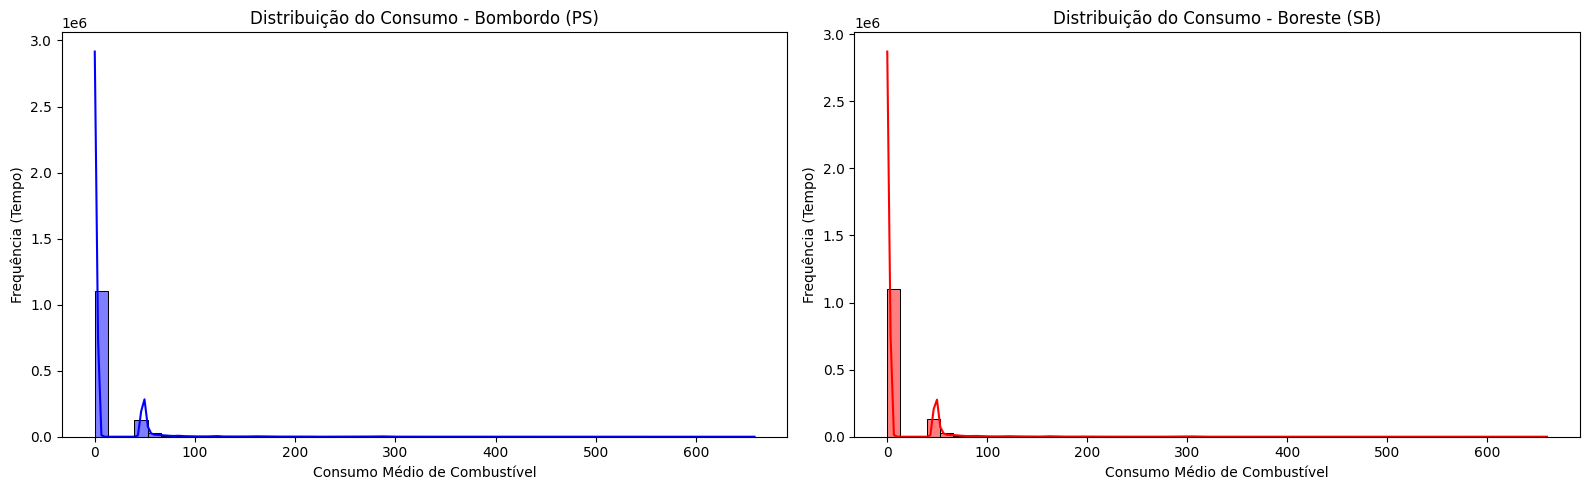

In [5]:
# Gráfico de distribuição de consumo
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# GRÁFICO 1: Bombordo (PS) na posição axes[0]
sns.histplot(data=df, x='ME_PS_AVG_FUEL_CONSUMPTION_RATE', bins=50, kde=True, color='blue', ax=axes[0])
axes[0].set_title('Distribuição do Consumo - Bombordo (PS)')
axes[0].set_xlabel('Consumo Médio de Combustível')
axes[0].set_ylabel('Frequência (Tempo)')

# GRÁFICO 2: Boreste (SB) na posição axes[1]
sns.histplot(data=df, x='ME_SB_AVG_FUEL_CONSUMPTION_RATE', bins=50, kde=True, color='red', ax=axes[1])
axes[1].set_title('Distribuição do Consumo - Boreste (SB)')
axes[1].set_xlabel('Consumo Médio de Combustível')
axes[1].set_ylabel('Frequência (Tempo)')

plt.tight_layout()
plt.show()

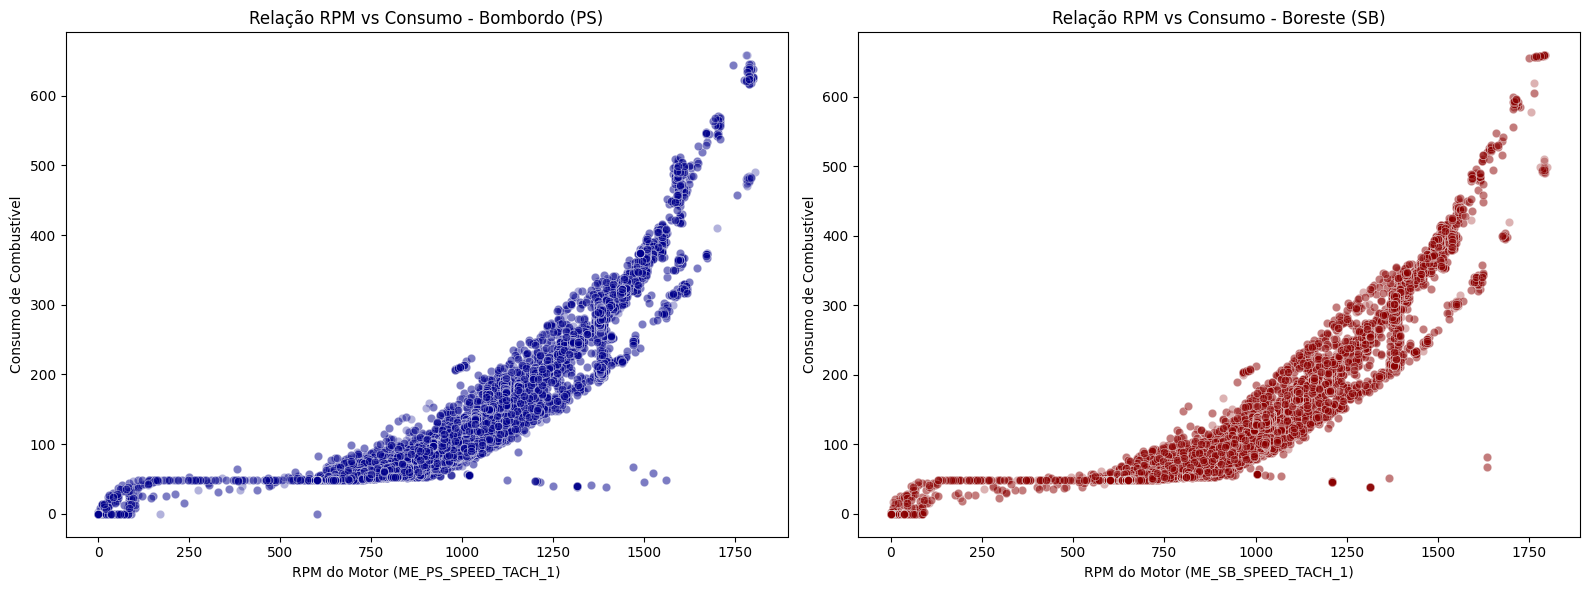

In [6]:
# Gráfico dispersão entre RPM e consumo combustível
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# GRÁFICO 1: Bombordo (PS) na posição axes[0]
sns.scatterplot(data=df, x='ME_PS_SPEED_TACH_1', y='ME_PS_AVG_FUEL_CONSUMPTION_RATE',
                alpha=0.3, color='darkblue', ax=axes[0])
axes[0].set_title('Relação RPM vs Consumo - Bombordo (PS)')
axes[0].set_xlabel('RPM do Motor (ME_PS_SPEED_TACH_1)')
axes[0].set_ylabel('Consumo de Combustível')

# GRÁFICO 2: Boreste (SB) na posição axes[1]
sns.scatterplot(data=df, x='ME_SB_SPEED_TACH_1', y='ME_SB_AVG_FUEL_CONSUMPTION_RATE',
                alpha=0.3, color='darkred', ax=axes[1])
axes[1].set_title('Relação RPM vs Consumo - Boreste (SB)')
axes[1].set_xlabel('RPM do Motor (ME_SB_SPEED_TACH_1)')
axes[1].set_ylabel('Consumo de Combustível')

plt.tight_layout()
plt.show()

O gráfico de distribuição mostra que a maior parte dos dados o consumo está em zero, onde deveremos análisar e filtrar esses casos que pode ser o momento que o motor esteja desligado.
O segundo gráfico de dispersão, mostra que o consumo possui uma relação com o RPM, quando maior o RPM, maior o consumo.

## Estatísticas Descritivas

In [7]:
# estatísticas descritivas básicas do dataset
df.describe().round(2)

,GENERATOR_PS_FUEL_RATE,GENERATOR_SB_FUEL_RATE,GPS_VTG_SPEED_OVER_GROUND_KNOTS,ISO Date,ME_PS_AFTERCOOLER_TEMP,ME_PS_AVG_FUEL_CONSUMPTION_RATE,ME_PS_ENGINE_LOAD,ME_PS_EXHAUST_GAS_TEMP_MANIFOLD_EVEN,ME_PS_EXHAUST_GAS_TEMP_MANIFOLD_ODD,ME_PS_JW_COOLANT_PRESSURE,ME_PS_JW_COOLANT_TEMP,ME_PS_OIL_PRESSURE,ME_PS_OIL_TEMP,ME_PS_SPEED_TACH_1,ME_SB_AFTERCOOLER_TEMP,ME_SB_AVG_FUEL_CONSUMPTION_RATE,ME_SB_ENGINE_LOAD,ME_SB_EXHAUST_GAS_TEMP_MANIFOLD_EVEN,ME_SB_EXHAUST_GAS_TEMP_MANIFOLD_ODD,ME_SB_JW_COOLANT_PRESSURE,ME_SB_JW_COOLANT_TEMP,ME_SB_OIL_PRESSURE,ME_SB_OIL_TEMP,ME_SB_SPEED_TACH_1,RUDD_PROP_PS_ACTUAL_RPM,RUDD_PROP_SB_ACTUAL_RPM
count,1300726.00,1300726.00,1300726.00,1300726,1300726.00,1300726.00,1300726.00,1300726.00,1300726.00,1300726.00,1300726.00,1300726.00,1300726.00,1300726.00,1300726.00,1300726.00,1300726.00,1300726.00,1300726.00,1300726.00,1300726.00,1300726.00,1300726.00,1300726.00,1300726.00,1300726.00
mean,5.48,7.04,0.40,2024-02-06 09:56:54.348167168,33.29,10.59,3.16,102.38,102.14,144.74,56.66,0.55,521.55,114.45,33.27,10.68,3.37,107.28,101.38,138.90,57.42,0.54,539.46,114.15,12.85,12.74
min,0.00,0.00,0.00,2023-11-15 00:00:09,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,0.00,0.00,0.00,2023-12-23 16:12:54,31.80,0.00,0.00,30.00,30.00,83.00,44.80,0.00,413.00,0.00,31.50,0.00,0.00,30.00,30.00,78.00,46.00,0.00,426.00,0.00,0.00,0.00
50%,0.00,0.00,0.10,2024-01-31 01:53:19,33.10,0.00,0.00,60.40,62.30,84.00,55.50,0.00,497.00,0.00,33.10,0.00,0.00,63.90,61.50,79.00,56.20,0.00,521.00,0.00,0.00,0.00
75%,13.20,16.90,0.20,2024-03-23 19:23:04,34.70,0.00,0.00,122.10,123.40,86.00,69.00,0.00,601.00,0.00,34.80,0.00,0.00,132.10,120.30,83.00,69.40,0.00,634.00,0.00,0.00,0.00
max,26.10,28.40,13.60,2024-04-30 23:59:49,50.10,658.20,100.00,722.70,714.70,2217.00,84.10,5.31,884.00,1805.00,48.20,659.50,100.00,724.20,709.90,2144.00,84.60,5.24,894.00,1800.00,218.00,218.00
std,7.16,8.86,1.08,NaN,2.24,33.21,9.97,106.13,102.89,173.47,13.35,1.33,130.58,281.11,2.32,33.80,10.38,108.41,101.85,166.95,13.15,1.29,131.26,279.95,32.78,32.54


## Boxplot


/tmp/ipykernel_41176/1702354234.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='FAIXA_RPM_PS', y='ME_PS_AVG_FUEL_CONSUMPTION_RATE', palette='Blues', ax=axes[0])
/tmp/ipykernel_41176/1702354234.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='FAIXA_RPM_SB', y='ME_SB_AVG_FUEL_CONSUMPTION_RATE', palette='Reds', ax=axes[1])


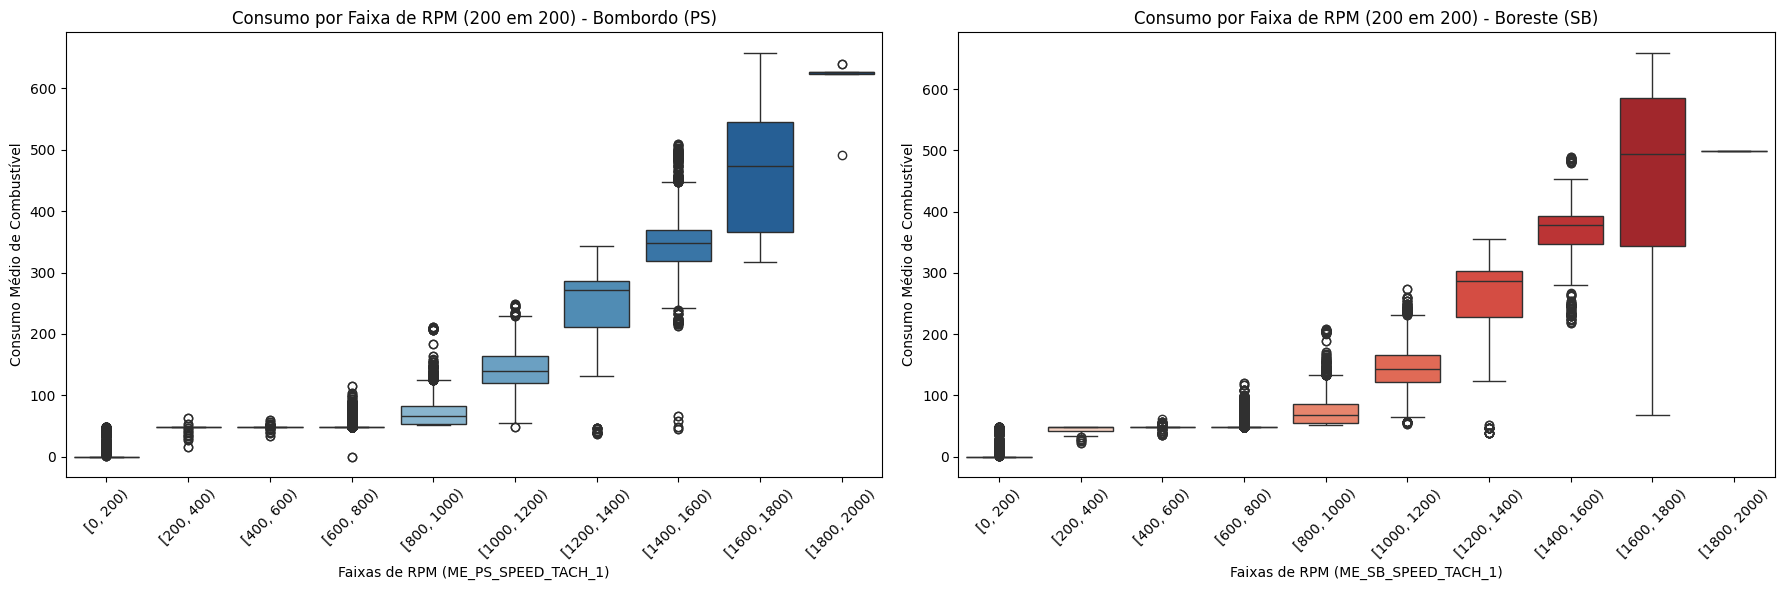

In [8]:
bins = list(range(0, 2200, 200))

df['FAIXA_RPM_PS'] = pd.cut(df['ME_PS_SPEED_TACH_1'], bins=bins, right=False)
df['FAIXA_RPM_SB'] = pd.cut(df['ME_SB_SPEED_TACH_1'], bins=bins, right=False)

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# GRÁFICO 1: Bombordo (PS) na posição axes[0]
sns.boxplot(data=df, x='FAIXA_RPM_PS', y='ME_PS_AVG_FUEL_CONSUMPTION_RATE', palette='Blues', ax=axes[0])
axes[0].set_title('Consumo por Faixa de RPM (200 em 200) - Bombordo (PS)')
axes[0].set_xlabel('Faixas de RPM (ME_PS_SPEED_TACH_1)')
axes[0].set_ylabel('Consumo Médio de Combustível')
axes[0].tick_params(axis='x', rotation=45)

# GRÁFICO 2: Boreste/Estibordo (SB) na posição axes[1]
sns.boxplot(data=df, x='FAIXA_RPM_SB', y='ME_SB_AVG_FUEL_CONSUMPTION_RATE', palette='Reds', ax=axes[1])
axes[1].set_title('Consumo por Faixa de RPM (200 em 200) - Boreste (SB)')
axes[1].set_xlabel('Faixas de RPM (ME_SB_SPEED_TACH_1)')
axes[1].set_ylabel('Consumo Médio de Combustível')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

O boxplot do consumo por faixa de ROM, mostra que temos um consumo a partir da faixa de 800 RPM, os consumo abaixo mostra que são outliers.

## Matriz de Correlação

In [9]:
# Matriz de correlação
print("\nMatriz de Correlação Completa:")

matriz_correlacao = df.select_dtypes(include='number').corr()
matriz_correlacao


Matriz de Correlação Completa:


,GENERATOR_PS_FUEL_RATE,GENERATOR_SB_FUEL_RATE,GPS_VTG_SPEED_OVER_GROUND_KNOTS,ME_PS_AFTERCOOLER_TEMP,ME_PS_AVG_FUEL_CONSUMPTION_RATE,ME_PS_ENGINE_LOAD,ME_PS_EXHAUST_GAS_TEMP_MANIFOLD_EVEN,ME_PS_EXHAUST_GAS_TEMP_MANIFOLD_ODD,ME_PS_JW_COOLANT_PRESSURE,ME_PS_JW_COOLANT_TEMP,ME_PS_OIL_PRESSURE,ME_PS_OIL_TEMP,ME_PS_SPEED_TACH_1,ME_SB_AFTERCOOLER_TEMP,ME_SB_AVG_FUEL_CONSUMPTION_RATE,ME_SB_ENGINE_LOAD,ME_SB_EXHAUST_GAS_TEMP_MANIFOLD_EVEN,ME_SB_EXHAUST_GAS_TEMP_MANIFOLD_ODD,ME_SB_JW_COOLANT_PRESSURE,ME_SB_JW_COOLANT_TEMP,ME_SB_OIL_PRESSURE,ME_SB_OIL_TEMP,ME_SB_SPEED_TACH_1,RUDD_PROP_PS_ACTUAL_RPM,RUDD_PROP_SB_ACTUAL_RPM
GENERATOR_PS_FUEL_RATE,1.000000,-0.607537,0.102646,-0.142727,0.118054,0.126092,0.140799,0.131552,0.135049,0.095141,0.156764,0.050314,0.154383,-0.160086,0.117051,0.129190,0.149407,0.139524,0.134469,0.124859,0.154861,0.135264,0.153923,0.151149,0.152195
GENERATOR_SB_FUEL_RATE,-0.607537,1.000000,0.118676,-0.123077,0.158756,0.154813,0.211291,0.209836,0.173422,0.180443,0.192132,0.194532,0.193307,-0.075796,0.156843,0.159172,0.215656,0.212949,0.173758,0.171612,0.191962,0.172512,0.192845,0.189232,0.187723
GPS_VTG_SPEED_OVER_GROUND_KNOTS,0.102646,0.118676,1.000000,-0.144333,0.415735,0.428059,0.475588,0.468488,0.533512,0.322632,0.590750,0.415236,0.581053,-0.196343,0.409046,0.448481,0.473780,0.465420,0.533017,0.329731,0.592013,0.388964,0.580532,0.605252,0.607143
ME_PS_AFTERCOOLER_TEMP,-0.142727,-0.123077,-0.144333,1.000000,-0.063071,-0.104045,-0.047356,-0.021987,-0.102192,0.218446,-0.217733,0.202627,-0.184802,0.538588,-0.061724,-0.111728,-0.060926,-0.048741,-0.109725,0.144504,-0.212978,0.109698,-0.182563,-0.174271,-0.173012
ME_PS_AVG_FUEL_CONSUMPTION_RATE,0.118054,0.158756,0.415735,-0.063071,1.000000,0.906301,0.815999,0.820933,0.972000,0.433257,0.802996,0.570461,0.887261,-0.142243,0.969914,0.881010,0.793710,0.783275,0.946933,0.439998,0.784087,0.530890,0.865697,0.884523,0.870171
ME_PS_ENGINE_LOAD,0.126092,0.154813,0.428059,-0.104045,0.906301,1.000000,0.837943,0.847572,0.922031,0.444307,0.813536,0.580199,0.874479,-0.180121,0.880312,0.935243,0.818392,0.808404,0.903592,0.452762,0.799419,0.542774,0.858950,0.913015,0.895471
ME_PS_EXHAUST_GAS_TEMP_MANIFOLD_EVEN,0.140799,0.211291,0.475588,-0.047356,0.815999,0.837943,1.000000,0.985553,0.864635,0.770368,0.832443,0.856690,0.875084,-0.170832,0.801012,0.835086,0.959509,0.941546,0.854860,0.765934,0.821961,0.829333,0.864939,0.888649,0.881092
ME_PS_EXHAUST_GAS_TEMP_MANIFOLD_ODD,0.131552,0.209836,0.468488,-0.021987,0.820933,0.847572,0.985553,1.000000,0.867347,0.777724,0.821268,0.861704,0.868481,-0.151233,0.805989,0.842491,0.964289,0.947970,0.857669,0.771509,0.811886,0.832197,0.858916,0.886483,0.879009
ME_PS_JW_COOLANT_PRESSURE,0.135049,0.173422,0.533512,-0.102192,0.972000,0.922031,0.864635,0.867347,1.000000,0.484028,0.889895,0.632914,0.951860,-0.190917,0.946848,0.907343,0.842176,0.829639,0.974436,0.490194,0.868326,0.587889,0.929709,0.947450,0.933668
ME_PS_JW_COOLANT_TEMP,0.095141,0.180443,0.322632,0.218446,0.433257,0.444307,0.770368,0.777724,0.484028,1.000000,0.510526,0.950312,0.529384,0.068806,0.427055,0.454248,0.764757,0.749573,0.482115,0.955819,0.505900,0.944259,0.525939,0.530545,0.528532


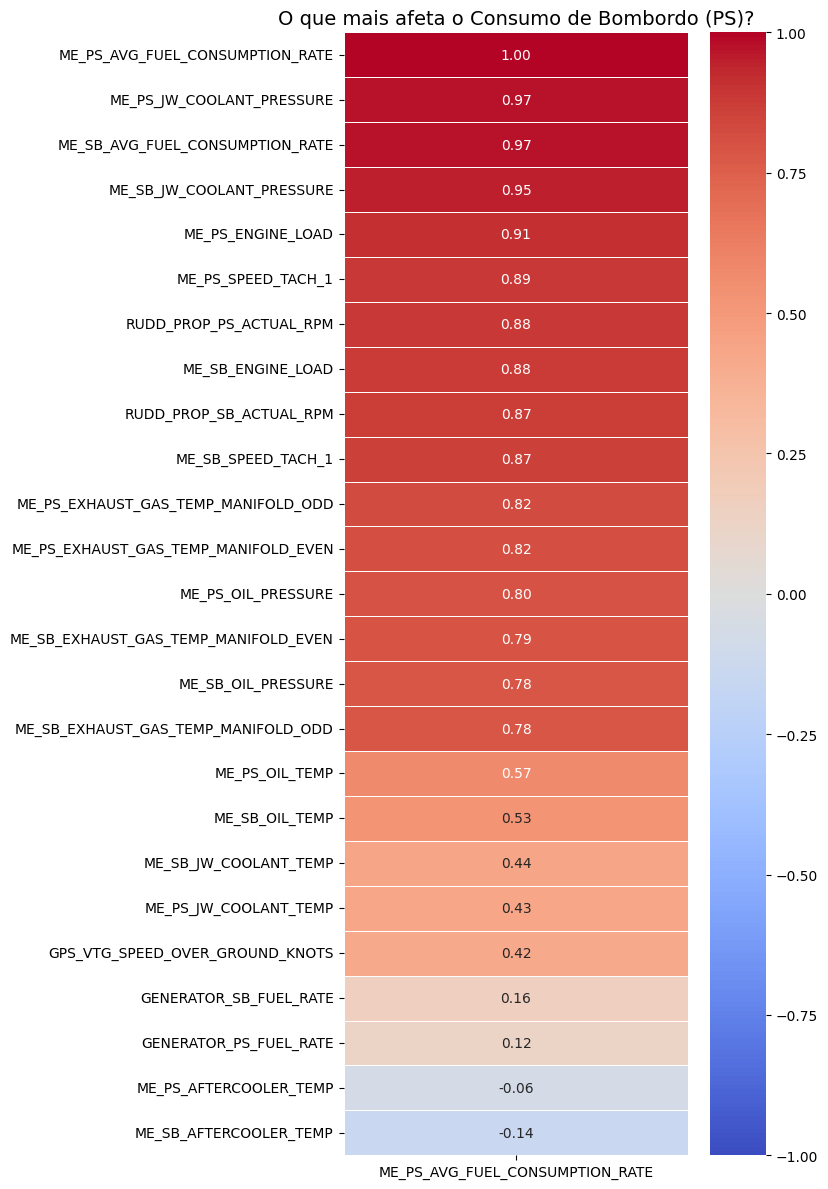

In [10]:
# Filtra APENAS a coluna de consumo de Bombordo (PS) e ordena do maior para o menor
corr_consumo = matriz_correlacao[['ME_PS_AVG_FUEL_CONSUMPTION_RATE']].sort_values(by='ME_PS_AVG_FUEL_CONSUMPTION_RATE', ascending=False)

# Plota um Heatmap vertical
plt.figure(figsize=(8, 12))

sns.heatmap(corr_consumo,
            annot=True,
            cmap='coolwarm',
            fmt=".2f",
            vmin=-1, vmax=1,
            linewidths=.5)

plt.title('O que mais afeta o Consumo de Bombordo (PS)?', fontsize=14)
plt.tight_layout()
plt.show()

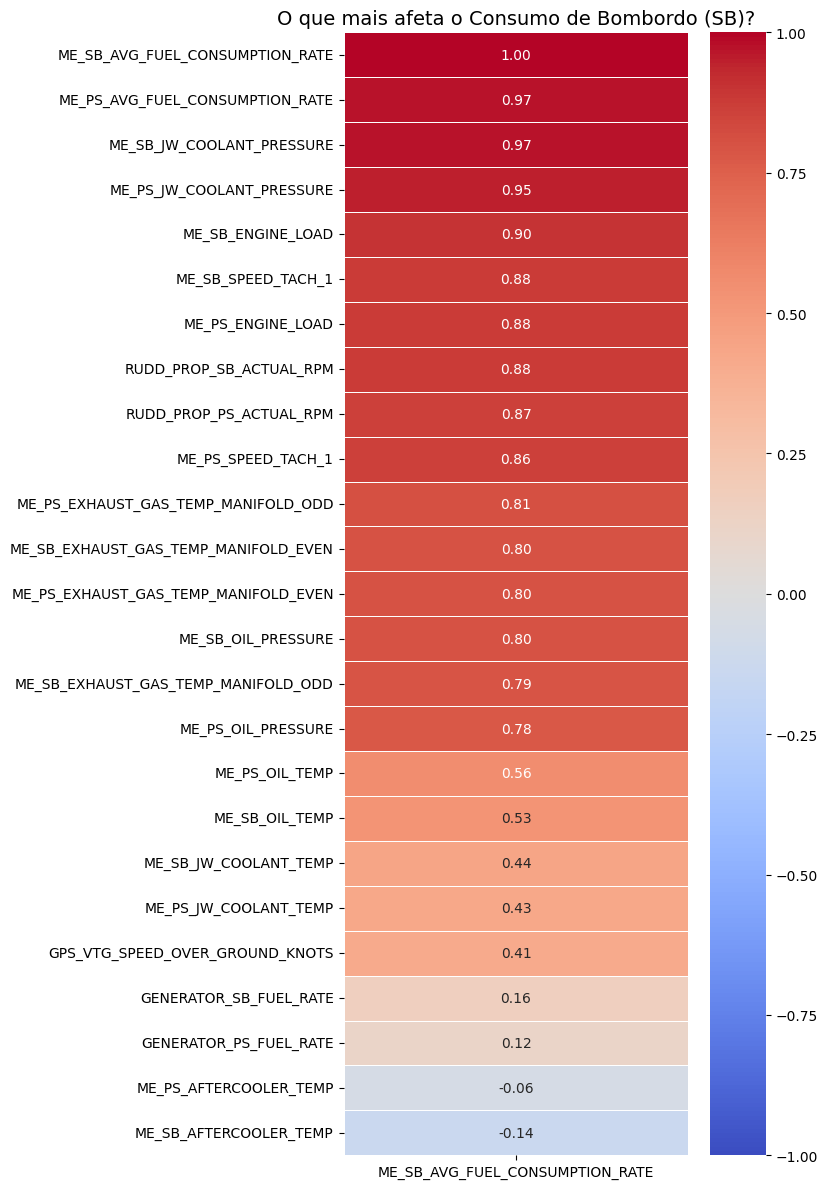

In [11]:
# Filtra APENAS a coluna de consumo de Bombordo (SB) e ordena do maior para o menor
corr_consumo = matriz_correlacao[['ME_SB_AVG_FUEL_CONSUMPTION_RATE']].sort_values(by='ME_SB_AVG_FUEL_CONSUMPTION_RATE', ascending=False)

# Plota um Heatmap vertical
plt.figure(figsize=(8, 12))

sns.heatmap(corr_consumo,
            annot=True,
            cmap='coolwarm',
            fmt=".2f",
            vmin=-1, vmax=1,
            linewidths=.5)

plt.title('O que mais afeta o Consumo de Bombordo (SB)?', fontsize=14)
plt.tight_layout()
plt.show()

O mapa de calor da matriz de correlação revela fortes correlações positivas entre as sensores onde possui uma força no motor, aumento de RPM, carga do motor, que por consequencia, possui ume elevação na temperetura e pressão de éleo do motor.

## Tratamento de Valores Nulos

O dataset Iris original não possui valores nulos. No entanto, o tratamento de valores nulos é crucial e pode envolver imputação (preenchimento com média, mediana, moda) ou remoção de linhas/colunas.

In [12]:
# Verificar a presença de valores nulos no dataset original
print("Valores nulos no dataset Iris:")
df.isnull().sum()

Valores nulos no dataset Iris:


,0
GENERATOR_PS_FUEL_RATE,0
GENERATOR_SB_FUEL_RATE,0
GPS_VTG_SPEED_OVER_GROUND_KNOTS,0
ISO Date,0
ME_PS_AFTERCOOLER_TEMP,0
ME_PS_AVG_FUEL_CONSUMPTION_RATE,0
ME_PS_ENGINE_LOAD,0
ME_PS_EXHAUST_GAS_TEMP_MANIFOLD_EVEN,0
ME_PS_EXHAUST_GAS_TEMP_MANIFOLD_ODD,0
ME_PS_JW_COOLANT_PRESSURE,0


## Outros ajustes/filtros
Quando o rebocador liga o motor, o RPM do motor fica om valor minimo de 650.
Para seguir a análise devemos filtrar a base para conter dados com RPM a partir desse valor 650.



In [13]:
df = df[(df['ME_PS_SPEED_TACH_1'] >= 650) & (df['ME_SB_SPEED_TACH_1'] >= 650)]

In [14]:
# selecionando sensores com maior correlação ao consumo
df = df[[
    'RUDD_PROP_PS_ACTUAL_RPM',
    'RUDD_PROP_SB_ACTUAL_RPM',
    'ME_SB_JW_COOLANT_PRESSURE',
    'ME_PS_JW_COOLANT_PRESSURE',
    'ME_SB_ENGINE_LOAD',
    'ME_PS_ENGINE_LOAD',
    'ME_SB_AVG_FUEL_CONSUMPTION_RATE',
    'ME_PS_AVG_FUEL_CONSUMPTION_RATE',
    'ME_PS_SPEED_TACH_1',
    'ME_SB_SPEED_TACH_1',
    'ME_PS_OIL_PRESSURE',
    'ME_SB_OIL_PRESSURE',
    'ME_SB_EXHAUST_GAS_TEMP_MANIFOLD_ODD',
    'ME_PS_EXHAUST_GAS_TEMP_MANIFOLD_ODD',
    'FAIXA_RPM_PS',
    'FAIXA_RPM_SB'
]]

# Pré-Processamento de Dados

O pré-processamento de dados é uma etapa crucial para preparar os dados para modelagem, garantindo que estejam no formato correto e otimizados para o desempenho do algoritmo.

In [15]:
# Definir os DOIS alvos juntos
alvos = ['ME_PS_AVG_FUEL_CONSUMPTION_RATE', 'ME_SB_AVG_FUEL_CONSUMPTION_RATE']
y = df[alvos]

# Definir as Features (X)
colunas_para_remover = alvos

if 'FAIXA_RPM_PS' in df.columns:
    colunas_para_remover.extend(['FAIXA_RPM_PS', 'FAIXA_RPM_SB'])

X = df.drop(colunas_para_remover, axis=1)

# Dividir os dados (o y_train e y_test agora terão 2 colunas cada)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

print(f"Dimensões de y_train: {y_train.shape}")

Dimensões de y_train: (105467, 2)


## Padronização

A padronização (ou Z-score scaling) transforma os dados para ter média 0 e desvio padrão 1. É útil para algoritmos que são sensíveis à escala das características, como SVMs ou redes neurais.

In [16]:
# Inicializar o StandardScaler
scaler_std = StandardScaler()

In [17]:
scaler_std.fit(X_train)

# Transformar os dados de treino e teste
X_train_standardized = scaler_std.transform(X_train)
X_test_standardized = scaler_std.transform(X_test)

In [18]:
df_standardized = pd.DataFrame(X_train_standardized, columns=X_train.columns, index=X_train.index)

In [19]:
# Exibir as primeiras linhas
print("\nPrimeiras 5 linhas dos dados padronizados (treino):")
print(df_standardized.head())


Primeiras 5 linhas dos dados padronizados (treino):
         RUDD_PROP_PS_ACTUAL_RPM  RUDD_PROP_SB_ACTUAL_RPM  \
916595                 -0.375542                -0.340912   
632579                 -2.339998                -1.955078   
216898                  0.778187                -0.340912   
1067429                -1.996997                -1.955078   
527697                  0.778187                 0.807630   

         ME_SB_JW_COOLANT_PRESSURE  ME_PS_JW_COOLANT_PRESSURE  \
916595                   -0.583191                  -0.637326   
632579                   -0.591212                  -0.622086   
216898                   -0.611267                   0.520945   
1067429                  -0.591212                  -0.599225   
527697                    0.656166                   0.627628   

         ME_SB_ENGINE_LOAD  ME_PS_ENGINE_LOAD  ME_PS_SPEED_TACH_1  \
916595           -0.320015          -0.421050           -0.687409   
632579           -1.329523          -1.318889      

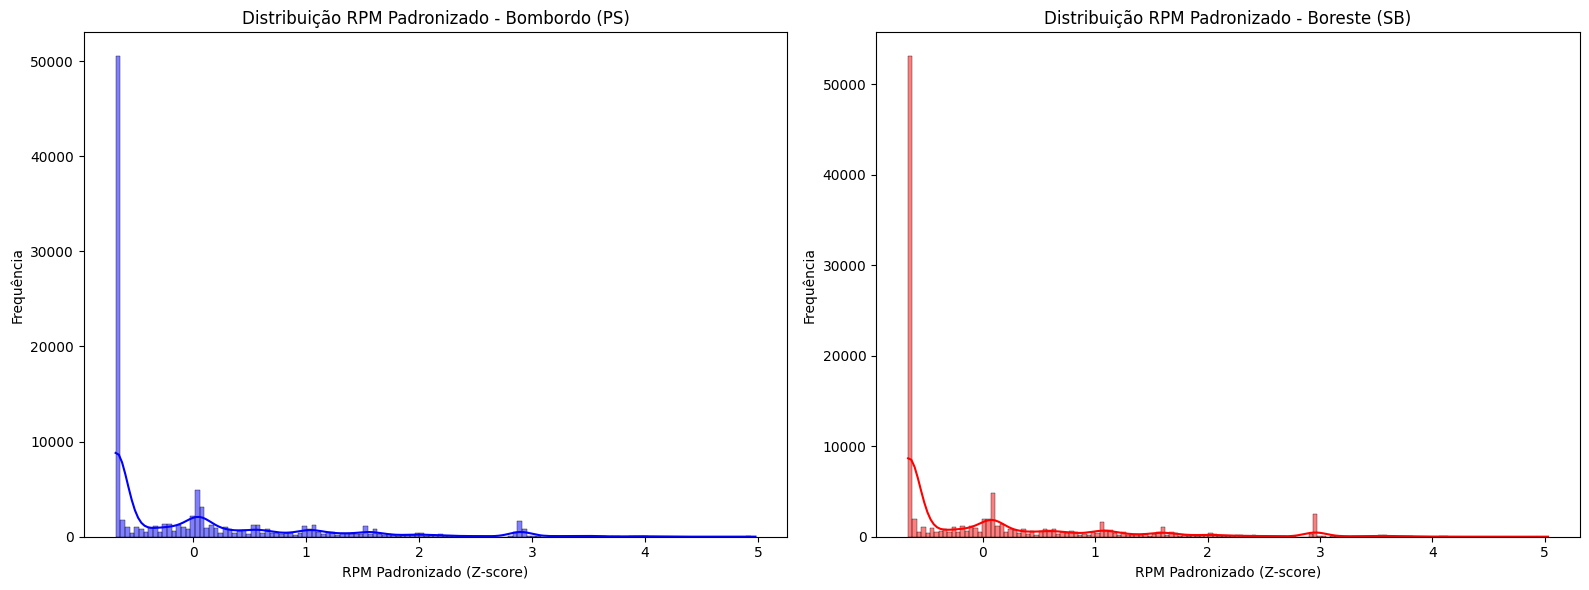

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# GRÁFICO 1: Bombordo (PS)
sns.histplot(df_standardized['ME_PS_SPEED_TACH_1'], kde=True, color='blue', ax=axes[0])
axes[0].set_title('Distribuição RPM Padronizado - Bombordo (PS)')
axes[0].set_xlabel('RPM Padronizado (Z-score)')
axes[0].set_ylabel('Frequência')

# GRÁFICO 2: Boreste (SB)
sns.histplot(df_standardized['ME_SB_SPEED_TACH_1'], kde=True, color='red', ax=axes[1])
axes[1].set_title('Distribuição RPM Padronizado - Boreste (SB)')
axes[1].set_xlabel('RPM Padronizado (Z-score)')
axes[1].set_ylabel('Frequência')

plt.tight_layout()
plt.show()

# Respondendo nossas hipóteses

Quais visualizações, tabelas e células descritivas respondem às hipóteses que você levantou?



## Hipótese 1

/tmp/ipykernel_41176/3268040375.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='FAIXA_RPM_PS', y='ME_PS_AVG_FUEL_CONSUMPTION_RATE',
/tmp/ipykernel_41176/3268040375.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='FAIXA_RPM_SB', y='ME_SB_AVG_FUEL_CONSUMPTION_RATE',


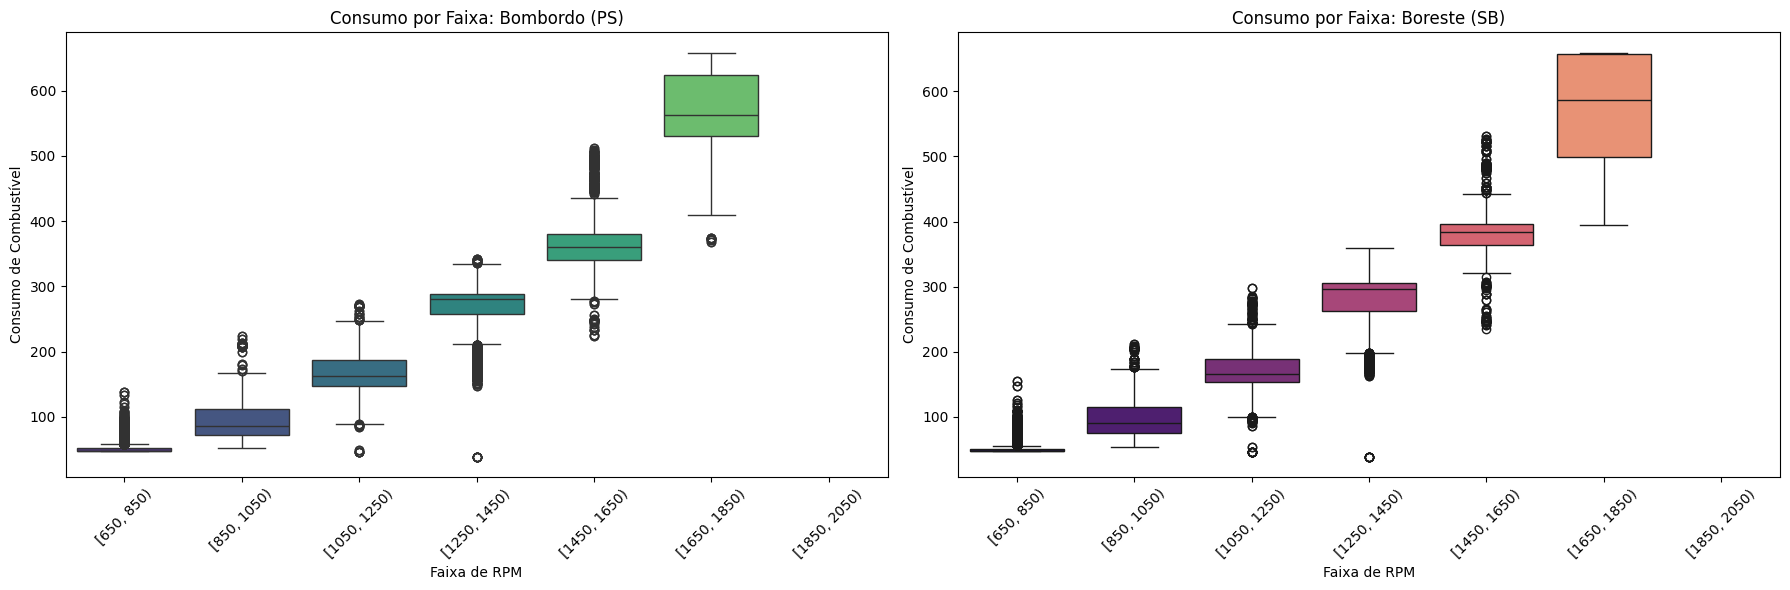

In [21]:
# Criar as faixas de RPM para ambos
bins = list(range(650, 2200, 200))
df['FAIXA_RPM_PS'] = pd.cut(df['ME_PS_SPEED_TACH_1'], bins=bins, right=False)
df['FAIXA_RPM_SB'] = pd.cut(df['ME_SB_SPEED_TACH_1'], bins=bins, right=False)

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Gráfico 1: Bombordo (PS)
sns.boxplot(data=df, x='FAIXA_RPM_PS', y='ME_PS_AVG_FUEL_CONSUMPTION_RATE',
            palette='viridis', ax=axes[0])
axes[0].set_title('Consumo por Faixa: Bombordo (PS)')
axes[0].set_xlabel('Faixa de RPM')
axes[0].set_ylabel('Consumo de Combustível')
axes[0].tick_params(axis='x', rotation=45)

# Gráfico 2: Boreste (SB)
sns.boxplot(data=df, x='FAIXA_RPM_SB', y='ME_SB_AVG_FUEL_CONSUMPTION_RATE',
            palette='magma', ax=axes[1])
axes[1].set_title('Consumo por Faixa: Boreste (SB)')
axes[1].set_xlabel('Faixa de RPM')
axes[1].set_ylabel('Consumo de Combustível')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

A análise visual dos boxplots mostra uma existência de uma faixa ideal de operação (sweet spot). Observa-se que a melhor relação de eficiência ocorre na janela entre 1050 e 1250 RPM, onde o motor entrega rotação útil com um consumo moderado e estável. A partir dos 1450 RPM, a mediana de consumo sofre saltos drásticos, indicando um custo alto de consumo.

## Hipótese 2

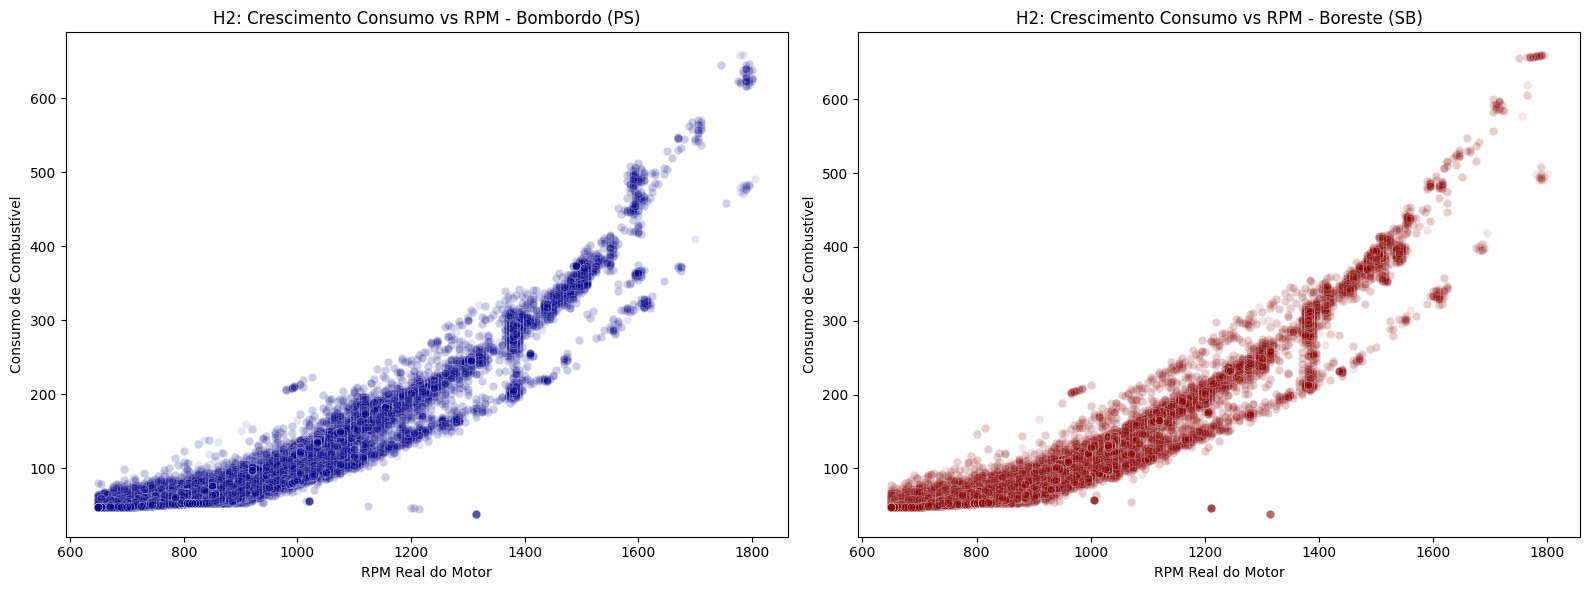

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

#  Gráfico 1: Bombordo (PS)
sns.scatterplot(data=df, x='ME_PS_SPEED_TACH_1', y='ME_PS_AVG_FUEL_CONSUMPTION_RATE',
                alpha=0.1, color='darkblue', ax=axes[0])
axes[0].set_title('H2: Crescimento Consumo vs RPM - Bombordo (PS)')
axes[0].set_xlabel('RPM Real do Motor')
axes[0].set_ylabel('Consumo de Combustível')

#  Gráfico 2: Boreste (SB)
sns.scatterplot(data=df, x='ME_SB_SPEED_TACH_1', y='ME_SB_AVG_FUEL_CONSUMPTION_RATE',
                alpha=0.1, color='darkred', ax=axes[1])
axes[1].set_title('H2: Crescimento Consumo vs RPM - Boreste (SB)')
axes[1].set_xlabel('RPM Real do Motor')
axes[1].set_ylabel('Consumo de Combustível')

# Ajusta os espaços e  o gráfico
plt.tight_layout()
plt.show()

A análise de dispersão demonstra que o crescimento do consumo de combustível não é linear. Em rotações baixas e médias (até aproximadamente 1200 RPM), o aumento do consumo é gradual e controlado. No entanto, ao ultrapassar a marca de 1400 RPM, a curva sofre uma inclinação para cima (crescimento exponencial). Isso comprova matematicamente que forçar os motores às suas rotações máximas gera um desperdício de combustível.

## Hipótese 3

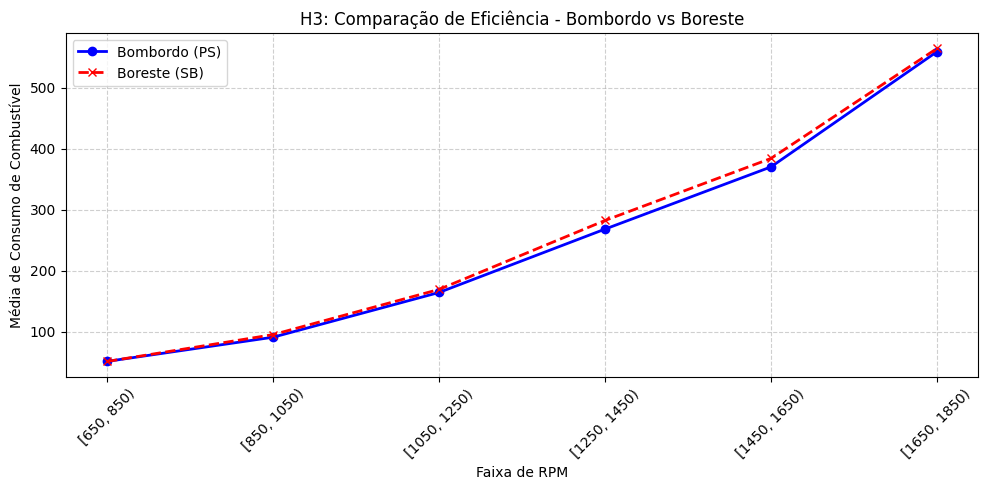

In [23]:
# hipótese 3


# Calcula a média de consumo para cada faixa de RPM de Bombordo (PS)
media_ps = df.groupby('FAIXA_RPM_PS', observed=False)['ME_PS_AVG_FUEL_CONSUMPTION_RATE'].mean()

# Faz o mesmo para Boreste (SB) na mesma faixa de RPM
df['FAIXA_RPM_SB'] = pd.cut(df['ME_SB_SPEED_TACH_1'], bins=bins, right=False)
media_sb = df.groupby('FAIXA_RPM_SB', observed=False)['ME_SB_AVG_FUEL_CONSUMPTION_RATE'].mean()

# Plota as duas linhas no mesmo gráfico
plt.figure(figsize=(10, 5))
plt.plot(media_ps.index.astype(str), media_ps.values, marker='o', label='Bombordo (PS)', color='blue', linewidth=2)
plt.plot(media_sb.index.astype(str), media_sb.values, marker='x', label='Boreste (SB)', color='red', linewidth=2, linestyle='--')

plt.title('H3: Comparação de Eficiência - Bombordo vs Boreste')
plt.xlabel('Faixa de RPM')
plt.ylabel('Média de Consumo de Combustível')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

O gráfico de linhas evidencia uma sobreposição quase perfeita entre as médias de consumo de combustível dos motores de Bombordo (linha azul) e Boreste (linha tracejada vermelha) em todas as faixas operacionais. Isso comprova estatisticamente a simetria de eficiência energética da embarcação. Na prática, este alinhamento indica que os dois motores estão com desgastes e calibrações muito semelhantes.

# Conclusão

É possível otimizar o consumo de combustível da embarcação através do controle inteligente das rotações (RPM).

A partir do cruzamento das nossas três hipóteses, estabelecemos as seguintes premissas operacionais:

- A Faixa ideal: A operação mais eficiente da embarcação ocorre quando os motores trabalham na janela entre 1050 e 1250 RPM. Nesta faixa, o equipamento entrega força de tração consistente com um custo energético altamente previsível e moderado.

- O Custo da Aceleração Máxima: O consumo de combustível tem um comportamento exponencial. Ultrapassar a barreira dos 1400 a 1450 RPM gera um desperdício severo. Operar o rebocador em sua capacidade máxima (acima de 1650 RPM) chega a custar o dobro de combustível.

- Saúde Mecânica e Simetria: A embarcação apresenta um balanço mecânico excelente. O comportamento espelhado entre Bombordo (PS) e Boreste (SB) indica que não há sobrecarga isolada em um dos eixos.